# 02: Exploring eye-tracking files and converting them to BIDS

**Who this is for:** new users of the Scully Center MEG lab.

During an MEG run, the **EyeLink 1000 Plus** records eye data and saves
it to one binary **`.edf`** file. This notebook converts that file to
[BIDS eye-tracking](https://bids-specification.readthedocs.io/en/latest/modality-specific-files/physiological-recordings.html)
files with **eye2bids**, then opens each output to see what's inside.

**What you will do:**

1. Install eye2bids and SR Research's `edf2asc` (once).
2. Copy the `.edf` into a `work/` folder inside your output folder, under its BIDS name.
3. Convert it with eye2bids.
4. Explore the outputs: gaze, pupil, head movement, fixations, saccades, and your experiment's messages.
5. Delete `work/`.

We use a patched copy of eye2bids, which handles the MEG lab's **Remote mode** setup (the camera
tracks a sticker on the forehead instead of a chin rest).

## 0. Setup

Do 0.1 and 0.2 **once**, in your Terminal. Then set your paths in 0.3 each time you use the notebook.

Use the same `pygers-meg` conda environment as notebook 01, on scotty (Option A) or your laptop (Option B).

### 0.1 Install eye2bids into the `pygers-meg` environment

eye2bids is a Python package. Activate your environment and install the pinned copy:

```bash
conda activate pygers-meg
pip install "git+https://github.com/mrribbits/eye2bids.git@0991c4c6e25b581b24a7011f8fdc103fddd7f26a"
```

The long string after `@` is a **commit ID**: it pins one exact version of the code, so everyone gets the same result. The MEG lab's eye-tracker settings (screen size, viewing distance, camera, …) come with it. Check it installed:

```bash
eye2bids --version
```

### 0.2 Install `edf2asc` (SR Research's EDF reader)

An `.edf` is a binary file only SR Research's software can read. eye2bids runs SR Research's command-line
tool **`edf2asc`** to turn it into text first, so `edf2asc` must be installed too. It is **not** a Python
package, so `pip` can't install it.

#### Option A: Cluster (scotty)

Use an install script to download `edf2asc` into a folder of your choice.
Replace `[...]` with a folder in your lab's partition, e.g. `/jukebox/yourlab/you/software`:

```bash
cd /jukebox/[...]
curl -fsSLO https://raw.githubusercontent.com/mrribbits/eye2bids/scully-config/eyetracking/install_edf2asc.sh
INSTALL_DIR=/jukebox/[...]/edf2asc bash install_edf2asc.sh
```

When it finishes, it prints a line like `export PATH="/jukebox/[...]/edf2asc/bin:$PATH"`. Add that line to
your `~/.bashrc`, so `edf2asc` is found in every new shell, then open a new shell and check:

```bash
which edf2asc
```

If you'd rather not change `~/.bashrc`, put the `/jukebox/[...]/edf2asc/bin` folder in `EDF2ASC_DIR` in 0.3
instead.

#### Option B: Local laptop (macOS)

The install script in Option A doesn't work on a Mac. Install SR Research's own package instead:

1. Make a free account on the [SR Research support forum](https://www.sr-research.com/support/) and wait for them to activate it.
2. Download and install the **EyeLink Developers Kit** for macOS
   ([download page](https://www.sr-research.com/support/thread-13.html)). It includes `edf2asc`.
3. Open a new Terminal window and check it's found:

   ```bash
   which edf2asc
   ```

   If this prints a path, leave `EDF2ASC_DIR = None` in 0.3. If it prints nothing, find the program with
   `mdfind -name edf2asc` and put **the folder that contains it** in `EDF2ASC_DIR`.

### Running this notebook from the pipeline

**Run the two cells below first, also when you run the notebook yourself.** They define `from_config()`,
which the settings cells use. Run by hand, `config_file` stays `None` and they change nothing: the notebook
uses the settings you edit in its cells. They let the Pygers-MEG-to-BIDS pipeline (`run_bids-pipeline.sh`) run this notebook
with the settings from a study's YAML files instead.

In pipeline mode, each settings cell ends with a line like
`EVENT_ID = from_config("EVENT_ID")`, which replaces the value typed above it with the one from the
YAML files. Run by hand, that line leaves the value as you typed it.

In [6]:
# Left as None when you run the notebook yourself. The pipeline replaces it with the path of its
# settings file (papermill adds a cell right below this one that sets it).
config_file = None

In [7]:
# Nothing to edit here. In pipeline mode (config_file set above), this reads this notebook's settings
# from the pipeline's settings file. Run by hand, PIPELINE stays None and from_config() changes nothing.
from pathlib import Path   # file paths that work on macOS, Linux and Windows

NOTEBOOK_ID = "02"     # this notebook's section in the pipeline's settings file
PIPELINE = None            # None = running by hand
if config_file is not None:
    import yaml                                       # reads .yaml files
    with open(config_file, encoding="utf-8") as f:
        PIPELINE = yaml.safe_load(f)[NOTEBOOK_ID]     # a dict: setting name -> value
    print(f"Pipeline mode: notebook {NOTEBOOK_ID} settings from {config_file}")


def from_config(*names):
    """The named settings: from the pipeline's settings file in pipeline mode, unchanged otherwise.

    Example:  EVENT_ID, DROP_UNMAPPED = from_config("EVENT_ID", "DROP_UNMAPPED")

    In pipeline mode every name must be in the settings file: a missing one stops the notebook, so a
    setting can never silently keep this notebook's example value. Settings the file lists under
    "_paths" are turned into Paths.
    """
    if PIPELINE is None:
        values = [globals()[name] for name in names]          # run by hand: keep the values typed above
    else:
        missing = [name for name in names if name not in PIPELINE]
        if missing:
            raise KeyError(f"The pipeline settings file has no value for {missing} (notebook {NOTEBOOK_ID}).")
        paths = set(PIPELINE.get("_paths", []))
        values = [Path(PIPELINE[name]) if name in paths and PIPELINE[name] is not None else PIPELINE[name]
                  for name in names]
    return values[0] if len(values) == 1 else tuple(values)

### 0.3 Set paths

Edit the lines between the `EDIT THESE LINES` markers, then run the cell. The labels (`SUBJECT`, `SESSION`, `TASK`, `RUN`) must match
the MEG recording this file goes with, as set in notebooks 04 and 05.

In [8]:
from pathlib import Path   # Path("...") turns text into a file path that works on macOS, Linux and Windows
import re                  # text patterns: used below to check the labels are letters and digits only

# ---- EDIT THESE LINES -------------------------------------------------------
# EDF_FILE: the raw .edf from the eye tracker. It is only read, never changed. It can keep whatever
# name the EyeLink gave it: Section 2 gives the copy in work/ the BIDS name built from the labels below.
EDF_FILE = Path("/jukebox/[yourpath]/auditory-oddball/sourcedata/sub-01/ses-01/raw/eye/sub-01_ses-01_task-oddballftcued.EDF")
#EDF_FILE = Path("EDIT ME/path/to/your_file.edf")

# The BIDS labels of the MEG recording this eye-tracking file goes with. They MUST be the same as
# SUBJECT, SESSION, TASK and RUN in notebooks 04 and 05: the file names are what tie the eye data to
# its MEG run. Labels may contain letters and digits only.
SUBJECT = "01"              # the part after "sub-"  (as text, in quotes)
SESSION = "01"              # the part after "ses-"; use None (no quotes) if you have no sessions
TASK    = "oddballftcued"   # the part after "task-"; also written as TaskName in the outputs
RUN     = None              # the part after "run-", e.g. "01"; use None if there is no run label

# OUT_DIR: a folder for this session's converted eye-tracking files, next to raw/ (eye-staging/).
# Created if it doesn't exist.
# (In a full BIDS dataset these files go in the meg/ folder next to the MEG data: see Section 6.)
OUT_DIR = Path("/jukebox/[yourpath]/data/auditory-oddball/sourcedata/sub-01/ses-01/eye-staging")

# METADATA_FILE: the eye-tracker settings (screen size, viewing distance, camera settings).
# None = the MEG lab's settings that come with eye2bids: leave it as None for recordings
# from the MEG lab. Only for a different setup, give your own .yml file instead.
METADATA_FILE = None
#METADATA_FILE = Path("EDIT ME/path/to/my_metadata.yml")

# EDF2ASC_DIR: the folder that contains edf2asc (see 0.2). None = your Terminal already finds it.
EDF2ASC_DIR = None
#EDF2ASC_DIR = Path("/jukebox/[...]/edf2asc/bin")   # scotty, after running install_edf2asc.sh
# -----------------------------------------------------------------------------

# Pipeline mode: these come from the YAML files (run by hand: unchanged). There, EDF_FILE is the one
# .edf in the session's raw eye/ folder, and OUT_DIR is the session's eye-staging/ folder.
EDF_FILE, SUBJECT, SESSION, TASK, RUN, OUT_DIR, METADATA_FILE, EDF2ASC_DIR = from_config(
    "EDF_FILE", "SUBJECT", "SESSION", "TASK", "RUN", "OUT_DIR", "METADATA_FILE", "EDF2ASC_DIR")

# Check the labels: BIDS allows only letters and digits in them (no "-", "_" or spaces).
# re.fullmatch() is True only if the WHOLE label matches the pattern [A-Za-z0-9]+.
for name, label in [("SUBJECT", SUBJECT), ("SESSION", SESSION), ("TASK", TASK), ("RUN", RUN)]:
    if label is not None and not re.fullmatch(r"[A-Za-z0-9]+", str(label)):
        raise ValueError(f'{name} = {label!r}: use letters and digits only (in quotes), e.g. "01".')

# The BIDS name of the recording, e.g. "sub-01_ses-01_task-oddballftcued".
# eye2bids names every output file after its input file, so Section 2 gives the .edf copy this name.
parts = [f"sub-{SUBJECT}"]
if SESSION:
    parts.append(f"ses-{SESSION}")
parts.append(f"task-{TASK}")
if RUN:
    parts.append(f"run-{RUN}")
BIDS_NAME = "_".join(parts)      # join the parts with "_" between them

# A subfolder for the working files: the copy of the .edf, the metadata copy, and the
# temporary .asc files that eye2bids makes. Section 5.6 deletes it at the end.
WORK_DIR = OUT_DIR / "work"

print("Raw .edf      :", EDF_FILE.name)
print("BIDS name     :", BIDS_NAME)
print("Task          :", TASK)
print("Output folder :", OUT_DIR)
print("Work folder   :", WORK_DIR)

Raw .edf      : sub-01_ses-01_task-oddballftcued.EDF
BIDS name     : sub-01_ses-01_task-oddballftcued
Task          : oddballftcued
Output folder : /jukebox/pinsk/MEG/pygers-meg/data/auditory-oddball/sourcedata/sub-01/ses-01/eye-staging
Work folder   : /jukebox/pinsk/MEG/pygers-meg/data/auditory-oddball/sourcedata/sub-01/ses-01/eye-staging/work


## 1. Imports

This cell loads the Python packages the notebook uses.

In [9]:
# "import x" makes package x usable; "import x as y" lets the code use the short name y;
# "from x import y" brings in only y.
import json                         # read and write .json sidecar files
import os                           # change the PATH setting (where programs are looked for)
import shutil                       # copy and delete files

import pandas as pd                 # tables: every .tsv file is read as a pandas DataFrame
import matplotlib.pyplot as plt     # plots
import yaml                         # read and write .yml files (installed with eye2bids)
from eye2bids.edf2bids import edf2bids   # the conversion function
from eye2bids.scully.metadata import load_metadata   # reads the MEG lab's settings (Section 3)

# Show up to 100 rows and 200 characters per cell, so long messages aren't cut off
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 200)

# If you set EDF2ASC_DIR, put that folder at the front of PATH, the list of folders searched for
# programs. Only this notebook is affected; nothing is changed on your computer.
if EDF2ASC_DIR is not None:
    os.environ["PATH"] = str(EDF2ASC_DIR) + os.pathsep + os.environ["PATH"]

## 2. Copy the `.edf` into `work/`

eye2bids writes two large temporary text files (`.asc`) **next to the input `.edf`**, and has no option to
put them anywhere else. So we don't run it on the raw file directly: that would put the `.asc` files in the
raw folder (or fail, if the raw folder is read-only). Instead we copy the `.edf` into `work/`, and the `.asc`
files land there too. Section 5.6 deletes `work/` when you're done.

The copy is also given the recording's **BIDS name** from Section 0.3 (e.g.
`sub-01_ses-01_task-oddballftcued.EDF`), because eye2bids names every output file after its input file.
That way the raw `.edf` can keep whatever name the EyeLink gave it.

Re-running is safe: the copy is skipped if an identical copy is already there.

In [10]:
import filecmp   # compares two files

# The copy gets the BIDS name from Section 0.3 (and the raw file's extension), so eye2bids names its
# outputs to match the MEG recording, whatever the raw file is called.
EDF_COPY = WORK_DIR / f"{BIDS_NAME}{EDF_FILE.suffix}"

WORK_DIR.mkdir(parents=True, exist_ok=True)   # make the folder (and any missing parents)

# Copy, unless an identical copy is already there. filecmp.cmp() first compares size and modification
# date (copy2 keeps the date), so if you point EDF_FILE at a different recording, it is copied again.
if EDF_COPY.exists() and filecmp.cmp(EDF_FILE, EDF_COPY):
    print("Already copied:", EDF_COPY)
else:
    shutil.copy2(EDF_FILE, EDF_COPY)          # copy2 also keeps the file's date
    print("Copied", EDF_FILE, "->", EDF_COPY)

# .stat().st_size is the file size in bytes; / 1e6 converts to megabytes (MB)
print(f"Size: {EDF_COPY.stat().st_size / 1e6:.1f} MB")

Copied /jukebox/pinsk/MEG/pygers-meg/data/auditory-oddball/sourcedata/sub-01/ses-01/raw/eye/sub-01_ses-01_task-oddballftcued.EDF -> /jukebox/pinsk/MEG/pygers-meg/data/auditory-oddball/sourcedata/sub-01/ses-01/eye-staging/work/sub-01_ses-01_task-oddballftcued.EDF
Size: 68.1 MB


## 3. The metadata file

Some facts about the recording are **not** in the `.edf`: the screen's physical size, how far the eyes
were from the screen, the camera lens, the institution, … The MEG lab's values come with eye2bids, in a
file called `eyelink_MEG_metadata.yml`, and eye2bids copies them into the JSON sidecars.

The other values (sampling rate, which eye, calibration results, screen resolution) eye2bids reads
from the `.edf` itself.

The cell below loads the MEG lab's settings (or your own file, if you set `METADATA_FILE` in 0.3), sets
`TaskName` to your `TASK` from 0.3, and saves the result in `work/` for eye2bids to read.
(The settings also end up in the JSON sidecars, so nothing is lost when `work/` is deleted.)

In [11]:
# load_metadata() reads a .yml file into a Python dictionary: {setting name: value}.
# Given None, it reads the MEG lab's file that comes with eye2bids.
metadata = load_metadata(METADATA_FILE)
print("Using", METADATA_FILE or "the MEG lab's settings that come with eye2bids")

# Fill in our task name
metadata["TaskName"] = TASK

# Save our copy and print it
STUDY_METADATA = WORK_DIR / f"{BIDS_NAME}_eyetrack-metadata.yml"
STUDY_METADATA.write_text(yaml.safe_dump(metadata, sort_keys=False))
print("Saved", STUDY_METADATA, "\n")
print(STUDY_METADATA.read_text())

Using the MEG lab's settings that come with eye2bids
Saved /jukebox/pinsk/MEG/pygers-meg/data/auditory-oddball/sourcedata/sub-01/ses-01/eye-staging/work/sub-01_ses-01_task-oddballftcued_eyetrack-metadata.yml 

SampleCoordinateSystem: gaze-on-screen
ScreenOrigin:
- top
- left
Units: pixel
SoftwareVersion: 5.51.53237
ScreenRefreshRate: 120
ScreenSize:
- 0.606
- 0.341
ScreenDistance: 0.94
EyeTrackerDistance: 0.61
RawDataFilters: 'EyeLink heuristic file sample filter: EXTRA (level 2)'
InstitutionName: Princeton University, Princeton Neuroscience Institute
InstitutionAddress: 40 Woodlands Way, Princeton, NJ 08540, USA
TaskName: oddballftcued



## 4. Convert with eye2bids

eye2bids does the whole conversion in one call. Behind the scenes it:

1. runs `edf2asc` twice, making two text files next to the `.edf` copy: `_events.asc` (messages, fixations,
   saccades, blinks) and `_samples.asc` (one line per sample),
2. reads them and writes the BIDS files into `OUT_DIR`.

It takes a minute or two. Its progress messages appear below.

The cell does the same as this Terminal command, which you can use later to convert files without the
notebook (`eye2bids -h` lists all its options):

```bash
eye2bids --input_file sub-01_ses-01_task-oddballftcued.EDF --task oddballftcued --output_dir <folder>
```

In [12]:
edf2bids(
    input_file=EDF_COPY,             # the renamed copy from Section 2
    metadata_file=STUDY_METADATA,    # our metadata copy from Section 3
    output_dir=OUT_DIR,              # where the BIDS files go
)

[23:30:47] INFO     input file found:                                                                ]8;id=15630194;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py\edf2bids.py]8;;\:]8;id=15630195;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py#50\50]8;;\
                    /jukebox/pinsk/MEG/pygers-meg/data/auditory-oddball/sourcedata/sub-01/ses-01/eye               
                    -staging/work/sub-01_ses-01_task-oddballftcued.EDF                                             

[23:30:49] INFO     Your input file contains multiple start times.                                  ]8;id=15630201;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py\edf2bids.py]8;;\:]8;id=15630202;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py#298\298]8;;\
                                                                                                                   
                                 As this is not seen as good practice in eyetracking experiments,                  
                                                                                                                   
                                 only the first start time will be kept for the metadata file.                     
                                                                                                                   
                                 Please consider changing your code accordingly                                    
                                 for future eyetracking experiments.                                               
                                                                                                                   

           INFO     file generated: sub-01_ses-01_task-oddballftcued_physio.json                    ]8;id=15630208;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py\edf2bids.py]8;;\:]8;id=15630209;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py#656\656]8;;\

           INFO     file generated: sub-01_ses-01_task-oddballftcued_physioevents.json              ]8;id=15630215;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py\edf2bids.py]8;;\:]8;id=15630216;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py#701\701]8;;\

           INFO     file generated: sub-01_ses-01_task-oddballftcued_events.json                    ]8;id=15630222;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py\edf2bids.py]8;;\:]8;id=15630223;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py#723\723]8;;\

[23:31:14] INFO     Remote mode detected: keeping target sticker columns.                           ]8;id=15630229;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py\edf2bids.py]8;;\:]8;id=15630230;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py#421\421]8;;\

[23:31:43] INFO     file generated:                                                                 ]8;id=15630236;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py\edf2bids.py]8;;\:]8;id=15630237;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py#447\447]8;;\
                    /jukebox/pinsk/MEG/pygers-meg/data/auditory-oddball/sourcedata/sub-01/ses-01/ey                
                    e-staging/sub-01_ses-01_task-oddballftcued_recording-eye1_physio.tsv.gz                        

[23:31:44] INFO     file generated:                                                                 ]8;id=15630243;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py\edf2bids.py]8;;\:]8;id=15630244;file:///usr/people/mpinsk/miniconda3/envs/pygers-meg/lib/python3.11/site-packages/eye2bids/edf2bids.py#784\784]8;;\
                    /jukebox/pinsk/MEG/pygers-meg/data/auditory-oddball/sourcedata/sub-01/ses-01/ey                
                    e-staging/sub-01_ses-01_task-oddballftcued_recording-eye1_physioevents.tsv.gz                  

## 5. What did eye2bids make?

| File | What it is |
|---|---|
| `…_recording-eye1_physio.tsv.gz` | **Samples**: one row per sample (every 2 ms at 500 Hz): time, gaze x/y, pupil size, plus 4 head-tracking columns |
| `…_recording-eye1_physio.json` | Describes the samples: column names and units, sampling rate, recorded eye, calibration, plus the metadata file's settings |
| `…_recording-eye1_physioevents.tsv.gz` | **Events** found by EyeLink (fixations, saccades, blinks) and every **message** your experiment sent to the tracker |
| `…_recording-eye1_physioevents.json` | Describes the events columns |
| `…_events.json` | The stimulus screen (size, distance, refresh rate, resolution), task name and institution. **Careful when moving it next to MEG data: see Section 6.** |

**`recording-eye1` doesn't mean the left eye.** It's the label for the first (here, the only) recorded eye.
`RecordedEye` in `_physio.json` says which eye it was.

In `work/` you'll also find the two temporary `.asc` files. They aren't BIDS files;
Section 5.6 deletes `work/`.

In [13]:
# List each file and its size. sorted() puts them in alphabetical order.
# .is_file() skips folders (the work/ subfolder); / 1e6 converts bytes to megabytes (MB).
print("Output folder:", OUT_DIR)
for f in sorted(OUT_DIR.iterdir()):
    if f.is_file():
        print(f"  {f.name:72s} {f.stat().st_size / 1e6:8.2f} MB")

print("\nwork folder:", WORK_DIR)
for f in sorted(WORK_DIR.iterdir()):
    print(f"  {f.name:72s} {f.stat().st_size / 1e6:8.2f} MB")

Output folder: /jukebox/pinsk/MEG/pygers-meg/data/auditory-oddball/sourcedata/sub-01/ses-01/eye-staging
  sub-01_ses-01_task-oddballftcued_events.json                                 0.00 MB
  sub-01_ses-01_task-oddballftcued_recording-eye1_physio.json                  0.00 MB
  sub-01_ses-01_task-oddballftcued_recording-eye1_physio.tsv.gz               12.97 MB
  sub-01_ses-01_task-oddballftcued_recording-eye1_physioevents.json            0.00 MB
  sub-01_ses-01_task-oddballftcued_recording-eye1_physioevents.tsv.gz          0.04 MB

work folder: /jukebox/pinsk/MEG/pygers-meg/data/auditory-oddball/sourcedata/sub-01/ses-01/eye-staging/work
  sub-01_ses-01_task-oddballftcued.EDF                                        68.05 MB
  sub-01_ses-01_task-oddballftcued_events.asc                                  0.41 MB
  sub-01_ses-01_task-oddballftcued_eyetrack-metadata.yml                       0.00 MB
  sub-01_ses-01_task-oddballftcued_samples.asc                               124.82 MB


### 5.1 The samples sidecar (`_physio.json`)

The values from the `.edf` and from the metadata file, plus a description of each column. Check:

- `SamplingFrequency` and `RecordedEye`,
- `CalibrationType`, `CalibrationCount` and the calibration errors (degrees of visual angle; lower is better),
- `Columns`: the column names of the `.tsv.gz`, which has **no header row** of its own.

In [14]:
physio_json = json.loads((OUT_DIR / f"{BIDS_NAME}_recording-eye1_physio.json").read_text())

# Print each field on its own line. Fields whose value is itself a dictionary (the column
# descriptions) are printed one level indented.
for key, value in physio_json.items():
    if isinstance(value, dict):
        print(f"{key}:")
        for sub_key, sub_value in value.items():
            print(f"    {sub_key}: {sub_value}")
    else:
        print(f"{key}: {value}")

Manufacturer: SR-Research
PhysioType: eyetrack
Columns: ['timestamp', 'x_coordinate', 'y_coordinate', 'pupil_size', 'target_x', 'target_y', 'target_distance', 'target_flags']
timestamp:
    Description: a continuously increasing identifier of the sampling time registered by the device
    Units: ms
    Origin: System startup
x_coordinate:
    LongName: Gaze position (x)
    Description: Gaze position x-coordinate of the recorded eye, in the coordinate units specified in the corresponding metadata sidecar.
    Units: pixel
y_coordinate:
    LongName: Gaze position (y)
    Description: Gaze position y-coordinate of the recorded eye, in the coordinate units specified in the corresponding metadata sidecar.
    Units: pixel
pupil_size:
    Description: Pupil area of the recorded eye as calculated by the eye-tracker in arbitrary units (see EyeLink's documentation for conversion).
    Units: a.u.
SoftwareVersion: 5.51.53237
EyeTrackerDistance: 0.61
RawDataFilters: EyeLink heuristic file sampl

### 5.2 The samples (`_physio.tsv.gz`)

Load the samples into a table. The column names come from `Columns` in the JSON above.

- **`timestamp`**: the tracker's clock in milliseconds (not seconds from the start of the run).
- **`x_coordinate`, `y_coordinate`**: where the eye was looking, in screen pixels from the top-left corner.
- **`pupil_size`**: pupil area in arbitrary units.
- **`target_x`, `target_y`, `target_distance`**: where the forehead sticker was. `target_distance` (mm) is a
  continuous record of **head movement** during the MEG run.
- **`target_flags`**: tracker warnings for that sample. `0` = none, `1` = sticker not found.

`n/a` means no value, for example during a blink. pandas shows these as `NaN`.

In [15]:
samples = pd.read_csv(
    OUT_DIR / f"{BIDS_NAME}_recording-eye1_physio.tsv.gz",
    sep="\t",                        # columns are separated by tabs
    header=None,                     # the file has no header row...
    names=physio_json["Columns"],    # ...so we give the column names from the JSON
    na_values="n/a",                 # treat "n/a" as missing
)

# Add a time column in seconds from the first sample: easier to read than the tracker's clock
samples["time_s"] = (samples["timestamp"] - samples["timestamp"].iloc[0]) / 1000

print(f"{len(samples):,} samples = {samples['time_s'].iloc[-1] / 60:.1f} minutes")
print(f"Gaze missing in {samples['x_coordinate'].isna().mean():.1%} of samples (blinks, looking away, ...)")
samples.head()     # the first 5 rows

1,678,062 samples = 56.1 minutes
Gaze missing in 8.4% of samples (blinks, looking away, ...)


,timestamp,x_coordinate,y_coordinate,pupil_size,target_x,target_y,target_distance,target_flags,time_s
0,6245341,965.1,544.2,546.0,4081.0,3949.0,610.9,0,0.000
1,6245343,963.8,546.3,546.0,4081.0,3949.0,610.9,0,0.002
2,6245345,962.4,548.4,546.0,4081.0,3949.0,610.9,0,0.004
3,6245347,959.8,549.9,546.0,4081.0,3950.0,610.9,0,0.006
4,6245349,957.0,550.8,546.0,4081.0,3950.0,610.9,0,0.008


**Tracker warnings.** How often was each warning value in `target_flags` seen? Mostly `0` is good. The
`_physio.json` above explains what each value means.

In [16]:
# value_counts() counts how many times each value appears
samples["target_flags"].value_counts()

target_flags
0    1656475
1      21587
Name: count, dtype: int64

### 5.3 Plot gaze, pupil and head distance

Top two panels: the first 60 seconds of gaze and pupil size. During blinks or lost tracking, gaze has
gaps and pupil size drops to 0.
Bottom panel: sticker-to-camera distance over the **whole** run. Slow drifts or jumps here are head
movements, worth comparing with the MEG head-position data.

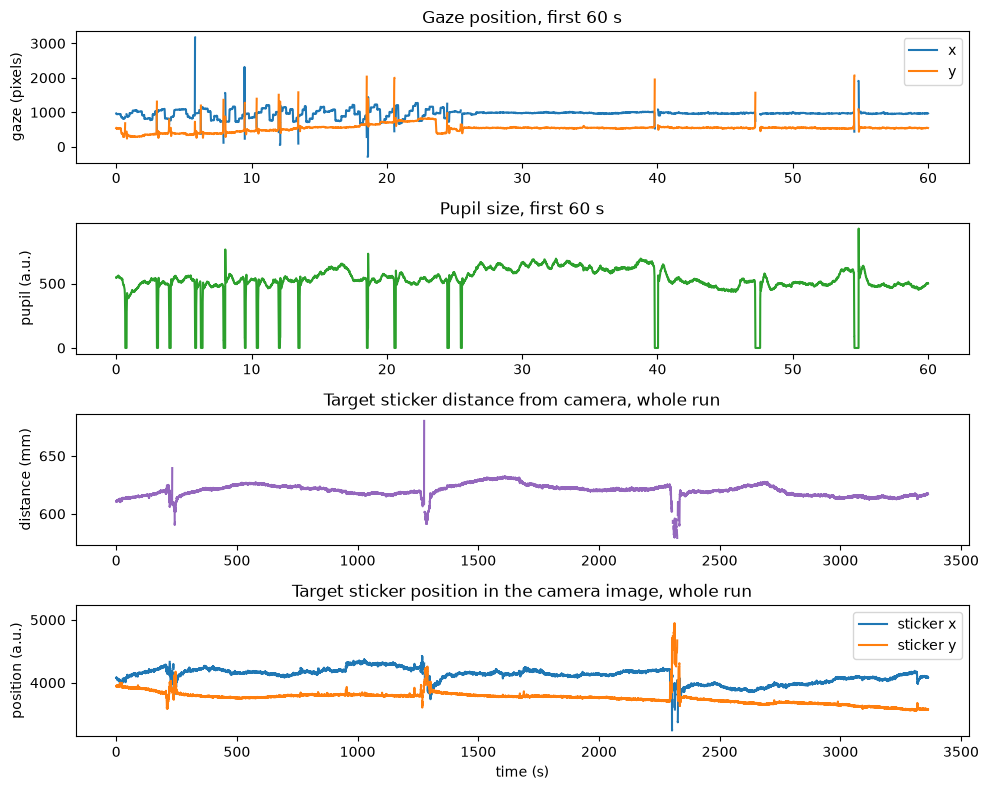

In [17]:
first_minute = samples[samples["time_s"] < 60]     # keep rows where time_s is below 60

# Four plots stacked vertically. figsize is (width, height) in inches.
fig, axes = plt.subplots(4, 1, figsize=(10, 8))

# 1. Gaze position
axes[0].plot(first_minute["time_s"], first_minute["x_coordinate"], label="x")
axes[0].plot(first_minute["time_s"], first_minute["y_coordinate"], label="y")
axes[0].set_ylabel("gaze (pixels)")
axes[0].set_title("Gaze position, first 60 s")
axes[0].legend()

# 2. Pupil size
axes[1].plot(first_minute["time_s"], first_minute["pupil_size"], color="tab:green")
axes[1].set_ylabel("pupil (a.u.)")
axes[1].set_title("Pupil size, first 60 s")

# 3. Head distance, whole run
axes[2].plot(samples["time_s"], samples["target_distance"], color="tab:purple")
axes[2].set_ylabel("distance (mm)")
axes[2].set_title("Target sticker distance from camera, whole run")

# 4. Target sticker x,y position, whole run
axes[3].plot(samples["time_s"], samples["target_x"], label="sticker x")
axes[3].plot(samples["time_s"], samples["target_y"], label="sticker y")
axes[3].set_ylabel("position (a.u.)")
axes[3].set_xlabel("time (s)")
axes[3].set_title("Target sticker position in the camera image, whole run")
axes[3].legend()

plt.tight_layout()     # stop the titles and labels from overlapping
plt.show()

### 5.4 The events (`_physioevents.tsv.gz`)

Each row is either something EyeLink detected or a message:

- **`trial_type`** = `fixation` or `saccade`, with a `duration` in ms. `blink` = 1 marks a saccade that is
  really part of a blink.
- **Messages** have an empty `trial_type` and the text in `message`: the tracker's settings, and every marker
  your experiment script sent (e.g. trial starts, stimulus onsets). These let you line up eye data with your task.

The first column holds the tracker's clock (ms), the same clock as `timestamp` in the samples.

In [18]:
physioevents_json = json.loads((OUT_DIR / f"{BIDS_NAME}_recording-eye1_physioevents.json").read_text())

events = pd.read_csv(
    OUT_DIR / f"{BIDS_NAME}_recording-eye1_physioevents.tsv.gz",
    sep="\t",
    header=None,
    names=physioevents_json["Columns"],
    na_values="n/a",
)

# How many fixations and saccades? dropna=False also counts the rows with no trial_type (messages)
print(events["trial_type"].value_counts(dropna=False), "\n")

# Average durations, in ms
print("Mean fixation duration:", round(events.loc[events["trial_type"] == "fixation", "duration"].mean()), "ms")
print("Mean saccade duration :", round(events.loc[events["trial_type"] == "saccade", "duration"].mean()), "ms")

trial_type
NaN         3868
fixation    1656
saccade     1653
Name: count, dtype: int64 

Mean fixation duration: 1799 ms
Mean saccade duration : 228 ms


**The messages.** Most messages after the tracker setup lines come from your experiment script. The
first count shows the most common message texts; the table after it shows the first 30 messages in order.

In [19]:
# Keep only the rows that have a message
messages = events[events["message"].notna()]

print(f"{len(messages)} messages. Most common:")
print(messages["message"].value_counts().head(15), "\n")

messages[["onset", "message"]].head(30)

3868 messages. Most common:
message
standard_onset                           1576
fixation_onset                            320
deviant_onset                             320
response_window_onset                     320
trial_outcome correct                     320
blink_cue                                 320
cue_onset_left                            160
cue_onset_right                           160
START                                       4
!MODE RECORD CR 500 2 2 2 2 R               4
END                                         4
RECCFG CR 500 2 2 2 2 R                     3
ELCLCFG LRRM                                3
GAZE_COORDS 0.00 0.00 1919.00 1079.00       3
ELCL_WINDOW_SIZES 176 188 176 188           3
Name: count, dtype: int64 



,onset,message
0,6245341,START
1,6245341,!MODE RECORD CR 500 2 2 2 2 R
2,6245457,EXPERIMENT_START
195,6272662,TRAINING_START
196,6272667,TRIALID 1
197,6272667,fixation_onset
198,6274170,cue_onset_left
199,6274677,standard_onset
200,6275913,standard_onset
201,6277066,standard_onset


### 5.5 The stimulus sidecar (`_events.json`)

A small file describing the screen the stimuli were shown on. **It contains no events.** In BIDS,
`_events.json` is the description file that goes with an `_events.tsv` listing the task trials. eye2bids
doesn't create that `.tsv`; the eye-movement events (fixations, saccades, blinks, messages) went into
`_physioevents.tsv.gz` instead (5.4). The trial list comes from elsewhere, e.g. the MEG events (Section 6).

Apart from the screen resolution, everything in it is copied from the metadata file (Section 3):

| Field | Comes from |
|---|---|
| `TaskName` | metadata file (set to your `TASK` in Section 3) |
| `InstitutionName`, `InstitutionAddress` | metadata file |
| `StimulusPresentation` → `ScreenDistance` (m) | metadata file |
| `StimulusPresentation` → `ScreenOrigin` | metadata file |
| `StimulusPresentation` → `ScreenRefreshRate` (Hz) | metadata file |
| `StimulusPresentation` → `ScreenSize` (m) | metadata file |
| `StimulusPresentation` → `ScreenResolution` (pixels) | the `.edf` (its `GAZE_COORDS` line) |

`ScreenResolution` should be `[1920, 1080]`. The official eye2bids writes `[1919, 1079]` (the last pixel's
number, not the pixel count); the patched version we're using fixes this.

**Empty values.** If a value is left empty in the metadata file, eye2bids drops `TaskName`,
`InstitutionName` or `InstitutionAddress` from this file, but writes `null` for an empty
`StimulusPresentation` value. The facility's metadata file fills them all, so you'll only see `null` if it
was edited. The cell below checks.

Section 6 explains why this file needs care when it's moved next to the MEG data.

In [20]:
# json.dumps(..., indent=4) turns the dictionary back into neatly indented text for printing
events_json = json.loads((OUT_DIR / f"{BIDS_NAME}_events.json").read_text())
print(json.dumps(events_json, indent=4))

# Check for empty (null) screen values. In Python, JSON's null becomes None.
# .items() goes through each field name and its value.
empty = [name for name, value in events_json["StimulusPresentation"].items() if value is None]
if empty:
    print("\nWARNING: no value for", empty, "- fill these in the metadata file (Section 3) and convert again")
else:
    print("\nAll StimulusPresentation values are filled in.")

{
    "TaskName": "oddballftcued",
    "InstitutionAddress": "40 Woodlands Way, Princeton, NJ 08540, USA",
    "InstitutionName": "Princeton University, Princeton Neuroscience Institute",
    "StimulusPresentation": {
        "ScreenDistance": 0.94,
        "ScreenOrigin": [
            "top",
            "left"
        ],
        "ScreenRefreshRate": 120,
        "ScreenSize": [
            0.606,
            0.341
        ],
        "ScreenResolution": [
            1920,
            1080
        ]
    }
}

All StimulusPresentation values are filled in.


### 5.6 Delete `work/`

Everything you need is now in the output folder. `work/` only holds the copy of the `.edf` (the original is
still in the raw folder), the metadata copy, and the two temporary `.asc` files, so it can go.

This deletes the folder. To keep the `.asc` files, set `KEEP_WORK = True` in the cell (or skip it). To run the notebook again later, just
start from the top: Section 2 makes a fresh copy.

In [21]:
KEEP_WORK = False   # True = keep work/ (e.g. to look at the .asc files); False = delete it
KEEP_WORK = from_config("KEEP_WORK")   # pipeline mode: from the YAML files

# shutil.rmtree() deletes a folder and everything inside it.
# The "if" makes re-running this cell safe: nothing happens if work/ is already gone.
if KEEP_WORK:
    print("KEEP_WORK = True, so work/ is kept:", WORK_DIR)
elif WORK_DIR.exists():
    shutil.rmtree(WORK_DIR)
    print("Deleted", WORK_DIR)
else:
    print("Already deleted:", WORK_DIR)

# What's left in the output folder
for f in sorted(OUT_DIR.iterdir()):
    print("  ", f.name)

Deleted /jukebox/pinsk/MEG/pygers-meg/data/auditory-oddball/sourcedata/sub-01/ses-01/eye-staging/work
   sub-01_ses-01_task-oddballftcued_events.json
   sub-01_ses-01_task-oddballftcued_recording-eye1_physio.json
   sub-01_ses-01_task-oddballftcued_recording-eye1_physio.tsv.gz
   sub-01_ses-01_task-oddballftcued_recording-eye1_physioevents.json
   sub-01_ses-01_task-oddballftcued_recording-eye1_physioevents.tsv.gz


## 6. Where these files go in a full BIDS dataset

Here everything went into one folder for this subject, so you can explore it on its own. In a full BIDS
dataset, the eye-tracking files go **in the `meg/` folder, next to the MEG recording they belong to**.
BIDS has no separate eye-tracking folder:

```
sub-01/ses-01/meg/
├── sub-01_ses-01_task-oddballftcued_meg.fif                         <- MEG data
├── sub-01_ses-01_task-oddballftcued_meg.json
├── sub-01_ses-01_task-oddballftcued_channels.tsv
├── sub-01_ses-01_task-oddballftcued_events.tsv                      <- MEG events
├── sub-01_ses-01_task-oddballftcued_events.json                     <- written by BOTH tools!
├── sub-01_ses-01_task-oddballftcued_recording-eye1_physio.tsv.gz    <- from this notebook
├── sub-01_ses-01_task-oddballftcued_recording-eye1_physio.json
├── sub-01_ses-01_task-oddballftcued_recording-eye1_physioevents.tsv.gz
└── sub-01_ses-01_task-oddballftcued_recording-eye1_physioevents.json
```

That's why the labels in Section 0.3 must match the MEG recording's (notebooks 04 and 05): the file names tie the eye data to its MEG run.

### Careful: `_events.json` must be merged, not copied over

Both eye2bids and the MEG-to-BIDS step (e.g. MNE-BIDS) write a file with **the same name**,
`<BIDS name>_events.json`, but with different contents:

- **MEG version:** describes the columns of the MEG `_events.tsv` (`onset`, `duration`, `trial_type`, …).
- **eye2bids version:** describes the stimulus screen (`StimulusPresentation`), plus `TaskName` and institution.

Copying the eye2bids file into `meg/` (or pointing `output_dir` at `meg/`) **overwrites the MEG version**,
and the descriptions of your MEG events are lost. Instead, the two have to be combined into one file.

**You don't need to do this by hand: notebook 05 (`05_Sync_eye_to_MEG.ipynb`) does this merge for you
in Step 10**, after it has synced the eye data to the MEG. It also lists any field the two files
disagree on, and saves the original MNE-BIDS file so the change can be undone. The example below shows
the idea, in two steps:

1. **Combine the two files:** every field from both. Where both have the same field, the MEG version is kept.
2. **Combine `StimulusPresentation` field by field.** Both files have this entry, but with different
   fields: eye2bids has the screen (`ScreenSize`, `ScreenDistance`, `ScreenResolution`, …), the MEG
   step has the software (`OperatingSystem`, `SoftwareName`, …). Step 1 alone would keep only the MEG
   entry and lose the screen fields, which BIDS requires for eye tracking in screen coordinates.

For example:

```python
meg_file = MEG_DIR / f"{BIDS_NAME}_events.json"   # MEG_DIR = the meg/ folder of your BIDS dataset
eye_file = OUT_DIR / f"{BIDS_NAME}_events.json"   # the one eye2bids wrote here

meg_json = json.loads(meg_file.read_text())
eye_json = json.loads(eye_file.read_text())

# Step 1: every field from both files (the MEG version wins where both have the same field)
merged = {**eye_json, **meg_json}
# Step 2: StimulusPresentation from both files, field by field (screen fields from eye2bids +
# software fields from the MEG step)
merged["StimulusPresentation"] = {**eye_json.get("StimulusPresentation", {}),
                                  **meg_json.get("StimulusPresentation", {})}
meg_file.write_text(json.dumps(merged, indent=4) + "\n")
```

The other four files have unique names and can be copied into `meg/` as they are.

## 7. Next steps

- **Line up eye and MEG.** Eye times are on the tracker's clock (ms); MEG times are seconds from the start
  of the MEG file. The messages your script sent to the tracker at the same moments as the MEG triggers
  are how the two are matched.